# 5주차 · 뉴런 하나 학습시키기

**이번 실습:** 뉴런 하나에서 순전파·역전파·가중치 갱신을 한 번 직접 계산합니다.  
**권장 시간:** 50분  
**준비:** 변수·곱셈·함수 입력과 출력

이 파일 하나를 위에서부터 순서대로 실행합니다. 주차 안의 이론 차시마다 별도 코드를 실행할 필요는 없습니다. 오른쪽 위 커널은 **Python (semi-ai)**로 고릅니다. `#` 뒤의 한국어 주석을 한 줄씩 읽고 실행해 주세요. 데이터는 교육용 합성 자료입니다.

## 1. 앞으로 계산하기

먼저 z, 활성화 a, 손실을 순서대로 구합니다. 중간값 a를 뒤의 미분 계산에 다시 씁니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [1]:
import numpy as np  # 지수 계산 도구입니다.
x = 2.0  # 입력입니다.
y = 1.0  # 정답입니다.
w = 0.5  # 시작 가중치입니다.
b = -1.0  # 시작 편향입니다.
z = w * x + b  # 가중합입니다.
a = 1 / (1 + np.exp(-z))  # 시그모이드 출력입니다.
before = (a - y) ** 2  # 제곱 손실입니다.
print(z, a, before)  # 중간값을 차례로 봅니다.

0.0 0.5 0.25


**실행 후 확인:** z=0, a=0.5, 손실=0.25입니다.

## 2. 뒤로 변화율 계산하기

각 조각은 ①손실 대 출력, ②출력 대 점수, ③점수 대 가중치 변화율입니다. 기울기를 모두 구한 뒤에만 w와 b를 바꿉니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [2]:
d_loss_a = 2 * (a - y)  # 출력 a가 변할 때 손실이 변하는 비율입니다.
d_a_z = a * (1 - a)  # 시그모이드의 변화율입니다.
d_z_w = x  # z=w*x+b에서 w의 영향은 x입니다.
dw = d_loss_a * d_a_z * d_z_w  # 세 조각을 곱한 w의 기울기입니다.
db = d_loss_a * d_a_z  # b의 영향은 1이라 두 조각만 곱합니다.
print(dw, db)  # 기울기를 봅니다.

-0.5 -0.25


**실행 후 확인:** dw=-0.5, db=-0.25입니다.

## 3. 조금 흔들어서 검산하기

w만 0.0001 높여 손실 변화를 봅니다. 정확한 미분과 아주 가까운 수가 나와야 합니다. 검산은 갱신 전에 합니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [3]:
epsilon = 0.0001  # 가중치를 아주 조금 바꿀 크기입니다.
shifted_a = 1 / (1 + np.exp(-((w + epsilon) * x + b)))  # w만 조금 키운 출력입니다.
shifted_loss = (shifted_a - y) ** 2  # 바뀐 출력의 손실입니다.
numerical = (shifted_loss - before) / epsilon  # 손실 변화량을 w 변화량으로 나눕니다.
print(dw, numerical)  # 역전파와 수치 검산을 비교합니다.

-0.5 -0.4999749983336521


**실행 후 확인:** 둘 다 약 -0.5입니다.

## 4. 배운 기울기로 갱신하기

역전파는 dw·db 계산까지입니다. 그다음 빼서 움직이는 것이 경사하강법입니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [4]:
learning_rate = 1.0  # 이번 예제의 보폭입니다.
w = w - learning_rate * dw  # 이전 상태에서 구한 dw로 갱신합니다.
b = b - learning_rate * db  # 이전 상태에서 구한 db로 갱신합니다.
new_a = 1 / (1 + np.exp(-(w * x + b)))  # 갱신 뒤 출력을 다시 계산합니다.
after = (new_a - y) ** 2  # 새 손실을 구합니다.
print(w, b, before, after)  # 전후를 비교합니다.

1.0 -0.75 0.25 0.049595351832811864


**실행 후 확인:** w=1, b=-0.75, 손실은 약 0.0496으로 줄어듭니다.

## 직접 바꾸기

첫 구역의 `x=2`를 3, `w=0.5`를 0, `b=-1`을 0으로 바꾸고 위에서부터 실행하세요. `dw`와 `db`를 비교하세요.

**해설:** a=0.5, dw=-0.75, db=-0.25입니다. 역전파는 기울기를 구하고, 경사하강법은 그 기울기로 숫자를 바꿉니다.

## 선택 · 같은 뉴런을 여러 번 갱신하기

한 번 계산을 이해했고 반복에 따른 손실 감소까지 보고 싶을 때만 실행합니다. 아래는 같은 입력과 정답으로 처음부터 다시 20번 반복하는 작은 계산입니다.

In [5]:
w = 0.5  # 가중치를 원래 출발점으로 되돌립니다.
b = -1.0  # 편향도 원래 출발점으로 되돌립니다.
learning_rate = 1.0  # 한 번의 보폭입니다.
loss_history = []  # 손실을 저장할 빈 목록입니다.
for count in range(20):  # 아래 계산을 20번 반복합니다.
    a = 1 / (1 + np.exp(-(w * x + b)))  # 현재 뉴런 출력을 구합니다.
    loss_history.append((a - y) ** 2)  # 갱신 전 손실을 기록합니다.
    dw = 2 * (a - y) * a * (1 - a) * x  # 현재 w의 기울기입니다.
    db = 2 * (a - y) * a * (1 - a)  # 같은 상태의 b 기울기입니다.
    w = w - learning_rate * dw  # w를 내리막 방향으로 옮깁니다.
    b = b - learning_rate * db  # b도 같은 이전 상태의 기울기로 옮깁니다.
print(loss_history[0], loss_history[-1])  # 첫 기록과 마지막 기록을 비교합니다.

0.25 0.0029195046800876154


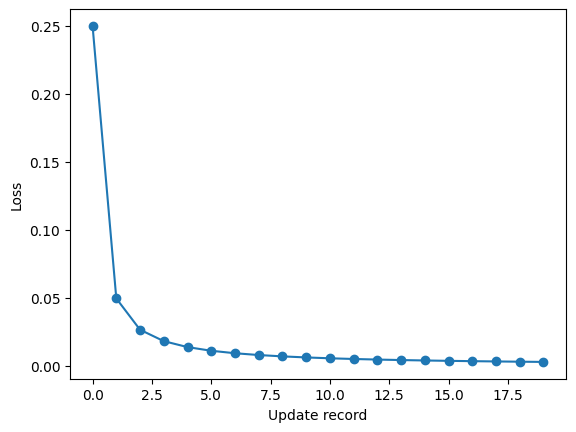

In [6]:
import matplotlib.pyplot as plt  # 그래프를 그리는 도구입니다.
plt.plot(loss_history, marker="o")  # 반복에 따른 손실을 그립니다.
plt.xlabel("Update record")  # 가로축은 기록 번호입니다.
plt.ylabel("Loss")  # 세로축은 손실입니다.
plt.show()  # 그래프를 보여 줍니다.